# 02 · Experiment E2 — telemetry downsampling on real flights (IDF-DS)

**Question (RQ1).** How does surveillance Age of Information translate into
error in the aircraft state the UTM is working from?

**Ground truth.** The IDF-DS SpeedyBee blackbox `navPos`/`navVel` stream at
~62 Hz. That rate matters: it resolves the 100–200 ms information-age regime,
which the original dataset plan had written off as unmeasurable.

**Method.** Resample the reference trajectory at 10 / 5 / 2 / 1 / 0.5 Hz, apply
added network latency, hold the latest received state, and compare against the
reference at a dense grid of decision times.

Two displacement quantities are reported and they are *not* the same:
`stale displacement` is the measured truth-vs-observed distance, while
`v · AoI` is the constant-velocity bound the research plan writes down (§7).
Comparing them shows where that bound breaks.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

from telemetry_freshness.viz import style as S, figures as F
S.use_paper_style()
print("working dir:", ROOT)

working dir: /path/to/Field_Measurement_of_Age_of_Information


In [2]:
from telemetry_freshness.data.idf_ds import IdfDsDataset
from telemetry_freshness.telemetry.generator import TrajectorySampler, generate_stream
from telemetry_freshness.telemetry.network_model import TelemetryConfig
from telemetry_freshness.surveillance.state_store import SurveillanceStateStore
from telemetry_freshness.surveillance.age_of_information import freshness_errors
from telemetry_freshness.core.rng import make_rng

ds = IdfDsDataset()
LAPS = ds.scenarios()[:12]          # 12 real flights
RATES_HZ  = [10, 5, 2, 1, 0.5]
LATENCY_MS = [0, 100, 250, 500, 1000]
print(f"{len(LAPS)} laps · reference rate {ds.reference_rate_hz(LAPS[0]):.1f} Hz")

12 laps · reference rate 61.7 Hz


In [3]:
records = []
for lap in LAPS:
    traj = ds.load_scenario(lap)
    s = TrajectorySampler(traj)
    t_eval = np.arange(s.t_start + 10, s.t_end - 5, 0.2)
    for rate in RATES_HZ:
        for lat_ms in LATENCY_MS:
            cfg = TelemetryConfig(update_rate_hz=rate, latency_ms=lat_ms,
                                  randomise_phase=True)
            store = SurveillanceStateStore()
            store.ingest(generate_stream(s, cfg, make_rng(2026, f"{lap}|{rate}|{lat_ms}")))
            f = freshness_errors(store, s, t_eval)
            f = f[f.tracked].copy()
            f["scenario_id"] = lap
            f["update_rate_hz"] = rate
            f["latency_ms"] = lat_ms
            records.append(f)

E2 = pd.concat(records, ignore_index=True)
print(f"{len(E2):,} decision-time observations")
E2.to_parquet("results/raw/E2_idfds_downsampling.parquet", index=False)

709,050 decision-time observations


### Summary across the sweep

In [4]:
summary = (E2.groupby(["update_rate_hz","latency_ms"])
    .agg(aoi_p50=("aoi_s","median"), aoi_p95=("aoi_s", lambda s: s.quantile(.95)),
         err_p50=("horiz_error_m","median"), err_p95=("horiz_error_m", lambda s: s.quantile(.95)),
         err_max=("horiz_error_m","max"),
         pred_p95=("predicted_displacement_m", lambda s: s.quantile(.95)),
         hdg_p95=("heading_error_deg", lambda s: s.quantile(.95)))
    .round(2).reset_index())
display(summary)
summary.to_csv("results/processed/E2_summary.csv", index=False)

,update_rate_hz,latency_ms,aoi_p50,aoi_p95,err_p50,err_p95,err_max,pred_p95,hdg_p95
0,0.5,0,1.01,1.91,9.95,26.43,51.97,26.65,31.82
1,0.5,100,1.16,1.99,11.01,27.95,54.32,28.26,34.17
2,0.5,250,1.25,2.12,12.55,30.58,57.48,30.82,37.97
3,0.5,500,1.51,2.37,15.00,34.58,64.62,35.01,43.36
4,0.5,1000,1.98,2.90,19.89,42.94,81.20,43.66,53.33
5,1.0,0,0.49,0.93,4.90,13.07,25.67,13.11,16.61
6,1.0,100,0.58,1.04,5.84,14.59,30.41,14.68,18.89
7,1.0,250,0.79,1.21,7.64,17.55,34.94,17.58,23.28
8,1.0,500,0.99,1.44,9.98,21.68,40.29,21.81,28.79
9,1.0,1000,1.50,1.95,15.53,30.35,52.63,30.60,42.06


## Figure F1 — Age of Information vs position error

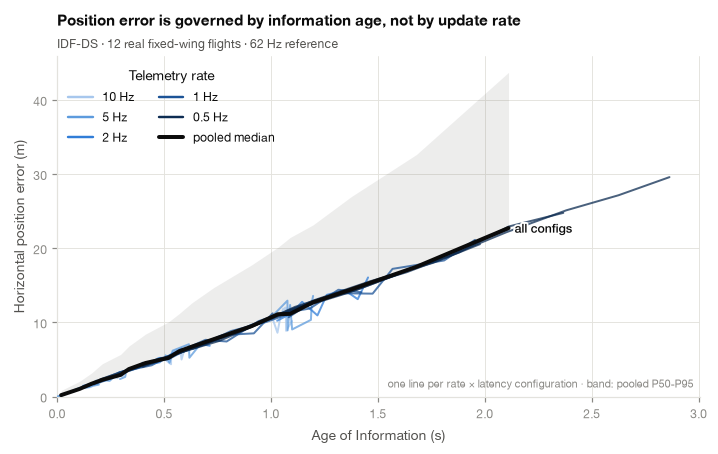

In [5]:
fig, ax = F.fig_aoi_vs_position_error(
    E2, level_col="update_rate_hz", aoi_col="aoi_s", err_col="horiz_error_m",
    subtitle=f"IDF-DS · {len(LAPS)} real fixed-wing flights · {ds.reference_rate_hz(LAPS[0]):.0f} Hz reference",
)
S.save(fig, "F1_aoi_vs_position_error"); S.plt.show()

## Does `v · AoI` bound the real displacement?

The research plan proposes `D_stale = v · AoI` as an interpretable measure. On a
straight leg it is exact; the question is what happens during real manoeuvres.

,measured error / (v · AoI)
p05,0.849
p50,0.995
p95,1.149
p99,1.319
frac_exceeding_bound,0.461


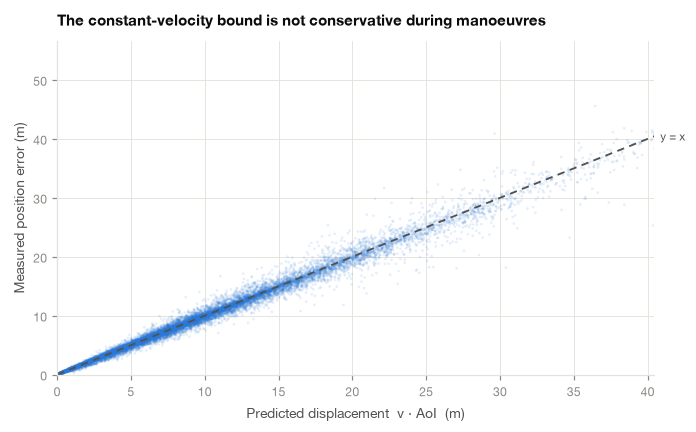

In [6]:
cmp = E2.dropna(subset=["predicted_displacement_m","horiz_error_m"]).copy()
cmp["ratio"] = cmp["horiz_error_m"] / cmp["predicted_displacement_m"].replace(0, np.nan)
r = cmp["ratio"].replace([np.inf,-np.inf], np.nan).dropna()
display(pd.Series({"p05": r.quantile(.05), "p50": r.median(), "p95": r.quantile(.95),
                   "p99": r.quantile(.99), "frac_exceeding_bound": float((r > 1).mean())
                  }).round(3).to_frame("measured error / (v · AoI)"))

fig, ax = S.plt.subplots(figsize=(6.4, 4.0))
sub = cmp.sample(min(20000, len(cmp)), random_state=0)
ax.scatter(sub.predicted_displacement_m, sub.horiz_error_m, s=3, alpha=0.12,
           color=S.CATEGORICAL[0], edgecolors="none")
lim = float(np.nanpercentile(sub.predicted_displacement_m, 99.5))
ax.plot([0, lim], [0, lim], color=S.INK["secondary"], lw=1.2, ls=(0,(4,3)))
ax.text(lim, lim, "  y = x", fontsize=7.5, color=S.INK["secondary"], va="center")
ax.set_xlim(0, lim); ax.set_ylim(0, lim*1.4)
ax.set_xlabel("Predicted displacement  v · AoI  (m)")
ax.set_ylabel("Measured position error (m)")
ax.set_title("The constant-velocity bound is not conservative during manoeuvres")
S.finish(fig, ax); S.save(fig, "S5_bound_vs_measured"); S.plt.show()

## Velocity and heading error

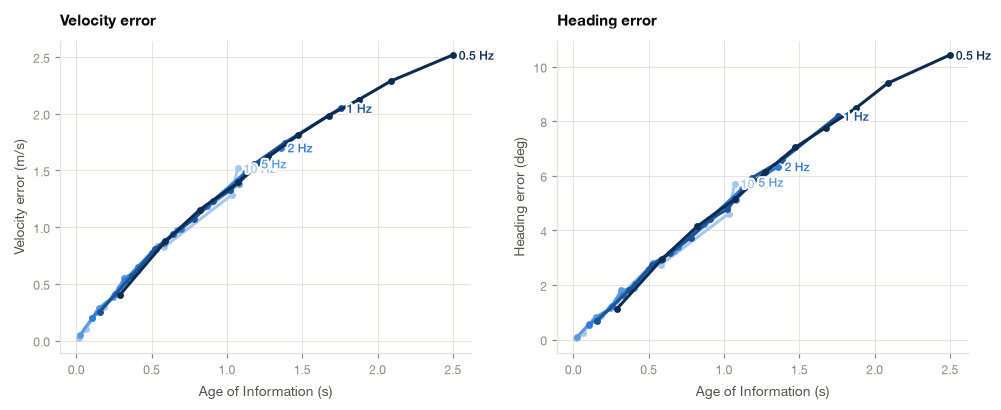

In [7]:
fig, axes = S.plt.subplots(1, 2, figsize=(9.2, 3.8))
for ax, col, lbl in ((axes[0], "vel_error_mps", "Velocity error (m/s)"),
                     (axes[1], "heading_error_deg", "Heading error (deg)")):
    rates = sorted(E2.update_rate_hz.unique(), reverse=True)
    for rate, c in zip(rates, S.sequential_colors(len(rates))):
        g = E2[E2.update_rate_hz == rate]
        b = (g.assign(_b=pd.qcut(g.aoi_s, 10, duplicates="drop"))
               .groupby("_b", observed=True)
               .agg(aoi=("aoi_s","median"), v=(col,"median")).dropna())
        ax.plot(b.aoi, b.v, color=c, marker="o", ms=3.5)
        S.direct_label(ax, b.aoi.iloc[-1], b.v.iloc[-1], f"{rate:g} Hz", c)
    ax.set_xlabel("Age of Information (s)"); ax.set_ylabel(lbl)
axes[0].set_title("Velocity error"); axes[1].set_title("Heading error")
S.finish(fig, axes); S.save(fig, "S6_velocity_heading_error"); S.plt.show()